# Laboratoare 1–2 · Regresia și Clasificarea
**Dataset:** Online Retail II (UCI) · **Metodologie:** CRISP-DM

| Fază CRISP-DM | Secțiune |
|---|---|
| 1. Înțelegerea sarcinii | 0 |
| 2. Înțelegerea datelor | 2 |
| 3. Pregătirea datelor | 3 |
| 4. Modelare | 4 (regresia) și 5 (clasificarea) |
| 5. Evaluare | 4.6 și 5.7–5.8 |
| 6. Implementare | 6 (+ aplicația Streamlit) |

## 0. Înțelegerea sarcinii (Business understanding)
**Context:** retailer online britanic (cadouri, mulți angrosiști), tranzacții 12.2009 – 12.2011.

**Întrebări:**
- **Lab 1 · Regresia:** *cât va cheltui* un client care cumpără în următoarele 90 de zile? (țintă continuă)
- **Lab 2 · Clasificarea:** *va cumpăra* clientul în următoarele 90 de zile? (țintă binară: da/nu)

**Decizie de design:** problema se împarte în două (cumpără? → cât?), deci regresia se antrenează doar pe clienții activi.

**Criterii de succes:** regresia bate baza (media) pe R², RMSE, MAE, MAPE; clasificarea bate baza pe ROC-AUC și F1.
Pentru ambele: fără supraantrenare (train ≈ test) și rezultat confirmat prin validare încrucișată.

## 1. Setup
Toate importurile și setările într-un singur loc; `SEED` face rezultatele reproductibile.

In [1]:
import json
import os
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (BaggingClassifier, GradientBoostingClassifier, GradientBoostingRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor, StackingClassifier,
                              StackingRegressor, VotingClassifier, VotingRegressor)
from sklearn.linear_model import (Lasso, LassoCV, LinearRegression, LogisticRegression, ElasticNetCV,
                                  RidgeCV, SGDRegressor)
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             accuracy_score, average_precision_score, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, mean_squared_error,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (KFold, RandomizedSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
os.environ["PYTHONWARNINGS"] = "ignore"          # și pentru procesele paralele (n_jobs=-1)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

try:                                   # `display` există în Jupyter/VS Code; în terminal îl înlocuim cu print
    display
except NameError:
    def display(obj):
        print(obj)

SEED = 42
ZILE_FEREASTRA = 90                    # fereastra "viitor" pentru țintă
CALE_CSV = os.environ.get("LAB_CSV")   # lasă None ca să descarce datasetul din Kaggle
ARTEFACTE = Path("artefacte")          # aici se salvează tot ce citește aplicația Streamlit
(ARTEFACTE / "figuri").mkdir(parents=True, exist_ok=True)


def salveaza_fig(nume):
    """Salvează figura curentă în artefacte/figuri și o afișează."""
    plt.gcf().savefig(ARTEFACTE / "figuri" / f"{nume}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 2. Înțelegerea datelor (Data understanding)
### 2.1 Încărcare
Identificatorii (`Invoice`, `StockCode`, `Customer ID`) sunt **etichete**, nu cantități: îi citim ca text.
În fișier `Customer ID` e scris `13085.0`, deci tăiem `.0`. Data o convertim în datetime (necesar pentru împărțirea în timp).

In [2]:
if CALE_CSV is None:
    import kagglehub
    folder = kagglehub.dataset_download("mashlyn/online-retail-ii-uci")
    CALE_CSV = next((str(p) for p in Path(folder).rglob("*.csv")), None)
assert CALE_CSV is not None, "Nu am găsit niciun .csv"

TIPURI = {"Invoice": str, "StockCode": str, "Customer ID": str}
df = pd.read_csv(CALE_CSV, dtype=TIPURI, parse_dates=["InvoiceDate"])
df["Customer ID"] = df["Customer ID"].str.replace(r"\.0$", "", regex=True)

print("Dimensiune:", df.shape)
print("Toate Customer ID au 5 cifre:", df["Customer ID"].dropna().str.fullmatch(r"\d{5}").all())
df.head()

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dimensiune: (1067371, 8)


Toate Customer ID au 5 cifre: True


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,13085,United Kingdom


### 2.2 Profilul coloanelor
Un singur tabel cu tipul, lipsurile, valorile unice și un exemplu pentru fiecare coloană, plus statistici pentru `Quantity` și `Price`.
Urmărim: tipuri corecte, unde sunt lipsurile, extreme (min negativ, max uriaș), intervalul de timp.

In [3]:
profil = pd.DataFrame({
    "tip": df.dtypes.astype(str),
    "lipsa": df.isna().sum(),
    "lipsa_%": (df.isna().mean() * 100).round(2),
    "valori_unice": df.nunique(),
    "exemplu": df.iloc[0],
})
display(profil)
display(df[["Quantity", "Price"]].describe())
print("Perioadă:", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())

,tip,lipsa,lipsa_%,valori_unice,exemplu
Invoice,object,0,0.000,53628,489434
StockCode,object,0,0.000,5305,85048
Description,object,4382,0.410,5698,15CM CHRISTMAS GLASS BALL 20 LIGHTS
Quantity,int64,0,0.000,1057,12
InvoiceDate,datetime64[ns],0,0.000,47635,2009-12-01 07:45:00
Price,float64,0,0.000,2807,6.950
Customer ID,object,243007,22.770,5942,13085
Country,object,0,0.000,43,United Kingdom


,Quantity,Price
count,"1,067,371.000","1,067,371.000"
mean,9.939,4.649
std,172.706,123.553
min,"-80,995.000","-53,594.360"
25%,1.000,1.250
50%,3.000,2.100
75%,10.000,4.150
max,"80,995.000","38,970.000"


Perioadă: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


### 2.3 Probleme de calitate (doar le măsurăm)
Fiecare problemă primește un număr, ca deciziile de curățare să vină din cifre.
Surse: documentația UCI vs. date (ex.: există și facturi cu prefix „A”, iar `StockCode` conține litere).

In [4]:
retur = df["Invoice"].str.startswith("C")
este_produs = df["StockCode"].str.match(r"^\d{5}")
probleme = pd.DataFrame({
    "problema": ["Customer ID lipsă", "Description lipsă", "Facturi anulate (prefix C)", "Facturi contabile (prefix A)",
                 "Quantity < 0", "Quantity < 0 fără factură C (ieșiri din stoc)", "Price == 0", "Price < 0",
                 "Duplicate complete", "StockCode fără 5 cifre (servicii/taxe)"],
    "rânduri": [df["Customer ID"].isna().sum(), df["Description"].isna().sum(), retur.sum(),
                df["Invoice"].str.startswith("A").sum(), (df["Quantity"] < 0).sum(),
                ((df["Quantity"] < 0) & ~retur).sum(), (df["Price"] == 0).sum(), (df["Price"] < 0).sum(),
                df.duplicated().sum(), (~este_produs).sum()],
})
probleme["% din total"] = (probleme["rânduri"] / len(df) * 100).round(2)
probleme.to_csv(ARTEFACTE / "probleme_calitate.csv", index=False)
display(probleme)
print("\nCele mai frecvente coduri non-produs:")
display(df.loc[~este_produs, "StockCode"].value_counts().head(15))

,problema,rânduri,% din total
0,Customer ID lipsă,243007,22.770
1,Description lipsă,4382,0.410
2,Facturi anulate (prefix C),19494,1.830
3,Facturi contabile (prefix A),6,0.000
4,Quantity < 0,22950,2.150
5,Quantity < 0 fără factură C (ieșiri din stoc),3457,0.320
6,Price == 0,6202,0.580
7,Price < 0,5,0.000
8,Duplicate complete,34335,3.220
9,StockCode fără 5 cifre (servicii/taxe),6093,0.570



Cele mai frecvente coduri non-produs:


StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
gift_0001_20      29
gift_0001_30      29
DCGSSGIRL         25
DCGSSBOY          23
PADS              19
Name: count, dtype: int64

## 3. Pregătirea datelor (Data preparation)
### 3.1 Curățare în straturi
**Principiu:** nu ștergem, ci *mutăm* rândurile în tabele separate (retururile și anomaliile ne trebuie la cheltuiala netă și la laboratorul de anomalii).
Ordinea contează: un rând intră în primul strat care îl prinde.
1. servicii / taxe / ajustări / vouchere (+ facturi „A”) → `administrative`
2. facturi anulate „C” → `retururi`
3. preț sau cantitate ≤ 0 (ieșiri din stoc, produse aruncate) → `ajustari_stoc`

**Decizii:** duplicatele se păstrează (produse scanate separat pe aceeași factură); rândurile fără `Customer ID` se păstrează (utile la coșuri), dar nu intră în tabelul de clienți.
Lista de coduri de serviciu e făcută după descriere și preț (`POST`, `DOT`, `M`, `D`, `BANK CHARGES`…), nu după regula „5 cifre”, care ar fi scos și produse reale (`DCGS…`, `PADS`).

In [5]:
COD_SERVICIU = r"POST|DOT|M|C2|D|S|BANK CHARGES|ADJUST2?|AMAZONFEE|CRUK|B|TEST\d+|gift_0001_\d+"

m1 = df["StockCode"].str.fullmatch(COD_SERVICIU, case=False) | df["Invoice"].str.startswith("A")
administrative = df[m1]
df1 = df[~m1]

m2 = df1["Invoice"].str.startswith("C")
retururi = df1[m2].copy()
df2 = df1[~m2]

m3 = (df2["Price"] <= 0) | (df2["Quantity"] <= 0)
ajustari_stoc = df2[m3]
tranzactii = df2[~m3].copy()

assert len(administrative) + len(retururi) + len(ajustari_stoc) + len(tranzactii) == len(df)

tranzactii["Valoare"] = tranzactii["Quantity"] * tranzactii["Price"]   # cât valorează linia
retururi["Valoare"] = retururi["Quantity"] * retururi["Price"]         # negativă

contabilitate = pd.DataFrame({
    "strat": ["1. servicii/taxe/vouchere", "2. anulări (C)", "3. preț/cantitate ≤ 0", "rămase: vânzări curate"],
    "rânduri": [len(administrative), len(retururi), len(ajustari_stoc), len(tranzactii)],
})
contabilitate["% din total"] = (contabilitate["rânduri"] / len(df) * 100).round(2)
contabilitate.to_csv(ARTEFACTE / "curatare.csv", index=False)
display(contabilitate)

print("Verificare reziduu: coduri non-5-cifre rămase în vânzări (trebuie să fie produse reale):")
display(tranzactii.loc[~tranzactii["StockCode"].str.match(r"^\d{5}"), "StockCode"].value_counts().head(10))
print("Clienți unici:", tranzactii["Customer ID"].nunique(), "| facturi:", tranzactii["Invoice"].nunique(),
      "| produse:", tranzactii["StockCode"].nunique())

,strat,rânduri,% din total
0,1. servicii/taxe/vouchere,5911,0.550
1,2. anulări (C),18286,1.710
2,3. preț/cantitate ≤ 0,6153,0.580
3,rămase: vânzări curate,1037021,97.160


Verificare reziduu: coduri non-5-cifre rămase în vânzări (trebuie să fie produse reale):


StockCode
DCGS0058     30
DCGSSGIRL    23
DCGSSBOY     21
PADS         17
DCGS0076     15
DCGS0003     13
DCGS0069      5
DCGS0004      4
DCGS0072      3
DCGS0068      2
Name: count, dtype: int64

Clienți unici: 5852 | facturi: 39516 | produse: 4896


### 3.2 Tabelul de clienți (un rând = un client)
Împărțim timpul la o **dată de tăiere** (ultimele 90 de zile = „viitor”). Variabilele (x) vin doar din *istoric*, ținta (y) doar din *viitor*, ca modelul să nu „vadă viitorul” (*data leakage*).
Variabile: RFM (Recency, Frequency, Monetary) + câteva extra. Cheltuiala e **netă** (vânzări − retururi), altfel comenzi anulate imediat (ex. 80.995 buc.) ar umfla artificial un client.

In [6]:
FINAL = tranzactii["InvoiceDate"].max()
CUTOFF = FINAL.normalize() - pd.Timedelta(days=ZILE_FEREASTRA)
print("Data de tăiere:", CUTOFF, "| sfârșit date:", FINAL)

vanzari = tranzactii[tranzactii["Customer ID"].notna()]
retur_cl = retururi[retururi["Customer ID"].notna()]
istoric_v, viitor_v = vanzari[vanzari["InvoiceDate"] < CUTOFF], vanzari[vanzari["InvoiceDate"] >= CUTOFF]
istoric_r, viitor_r = retur_cl[retur_cl["InvoiceDate"] < CUTOFF], retur_cl[retur_cl["InvoiceDate"] >= CUTOFF]

g = istoric_v.groupby("Customer ID")
clienti = pd.DataFrame({
    "recenta_zile":      (CUTOFF - g["InvoiceDate"].max()).dt.days,     # cât de recent a cumpărat
    "vechime_zile":      (CUTOFF - g["InvoiceDate"].min()).dt.days,     # de când e client
    "frecventa":         g["Invoice"].nunique(),                        # nr. de facturi
    "produse_distincte": g["StockCode"].nunique(),
    "cantitate_totala":  g["Quantity"].sum(),
    "vanzari_brute":     g["Valoare"].sum(),
    "uk":                (g["Country"].first() == "United Kingdom").astype(int),
})
clienti["retururi_val"] = istoric_r.groupby("Customer ID")["Valoare"].sum().reindex(clienti.index).fillna(0)
ultimele = istoric_v[istoric_v["InvoiceDate"] >= CUTOFF - pd.Timedelta(days=ZILE_FEREASTRA)]
clienti["vanzari_ultimele_90z"] = ultimele.groupby("Customer ID")["Valoare"].sum().reindex(clienti.index).fillna(0)
clienti["valoare_medie_factura"] = clienti["vanzari_brute"] / clienti["frecventa"]
clienti["rata_retur"] = (clienti["retururi_val"].abs() / clienti["vanzari_brute"]).clip(upper=1)

# ținta: cheltuiala netă în fereastra viitoare (0 dacă n-a cumpărat) + eticheta pentru clasificare
tinta = (viitor_v.groupby("Customer ID")["Valoare"].sum()
         .add(viitor_r.groupby("Customer ID")["Valoare"].sum(), fill_value=0))
clienti["tinta_cheltuiala"] = tinta.reindex(clienti.index).fillna(0)
clienti["a_cumparat"] = clienti.index.isin(viitor_v["Customer ID"])

print(f"Clienți cu istoric: {len(clienti)} | au cumpărat în fereastră: {clienti['a_cumparat'].sum()} ({clienti['a_cumparat'].mean():.1%})")
print(f"Țintă == 0: {(clienti['tinta_cheltuiala'] == 0).mean():.1%} | țintă < 0: {(clienti['tinta_cheltuiala'] < 0).sum()}")
display(clienti.describe().T)

Data de tăiere: 2011-09-10 00:00:00 | sfârșit date: 2011-12-09 12:50:00


Clienți cu istoric: 5256 | au cumpărat în fereastră: 2289 (43.6%)
Țintă == 0: 56.0% | țintă < 0: 33


,count,mean,std,min,25%,50%,75%,max
recenta_zile,"5,256.000",205.888,174.373,0.000,49.000,163.000,324.000,647.000
vechime_zile,"5,256.000",430.671,180.690,0.000,310.000,473.000,586.000,647.000
frecventa,"5,256.000",5.711,11.214,1.000,1.000,3.000,6.000,284.000
produse_distincte,"5,256.000",74.557,104.980,1.000,18.000,41.000,92.000,"2,178.000"
cantitate_totala,"5,256.000","1,662.785","8,152.417",1.000,175.000,451.500,"1,244.250","297,934.000"
vanzari_brute,"5,256.000","2,672.243","12,407.319",1.550,322.287,798.000,"2,106.925","484,615.100"
uk,"5,256.000",0.913,0.282,0.000,1.000,1.000,1.000,1.000
retururi_val,"5,256.000",-87.951,"1,218.467","-77,183.600",-25.610,0.000,0.000,0.000
vanzari_ultimele_90z,"5,256.000",348.806,"1,947.067",0.000,0.000,0.000,268.858,"62,151.700"
valoare_medie_factura,"5,256.000",377.871,640.286,1.550,178.633,282.373,417.980,"25,784.320"


### 3.3 Variabile transformate și cele două tabele de lucru
- Variabilele cu coadă lungă primesc `log1p` (regresia liniară și KNN sunt sensibile la extreme).
- **Regresie:** doar clienții care au cumpărat și au cheltuială netă ≥ 1 £ (peste jumătate din clienți au ținta 0; prag minim ca MAPE să nu împartă la ~0). Ținta se modelează ca `log1p`.
- **Clasificare:** toți clienții, eticheta `a_cumparat`.

Rânduri în tabelul de regresie: 2281 | în cel de clasificare: 5256


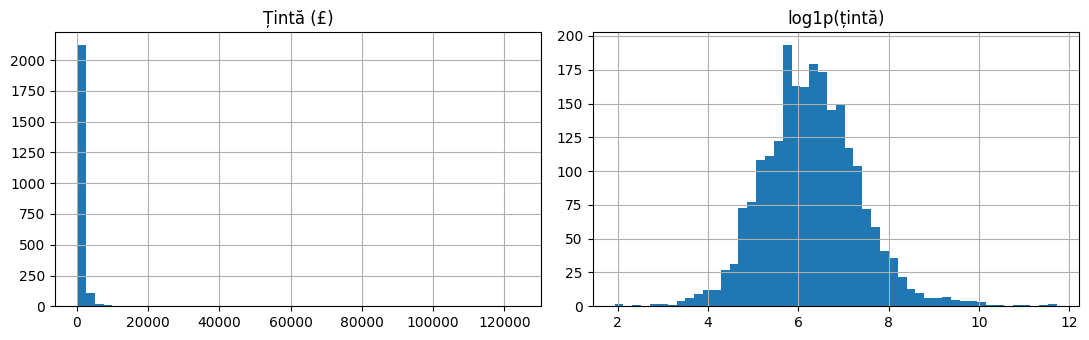

In [7]:
def transforma(c):
    """Variabilele de intrare (x): scară originală sau log1p pentru cele cu coadă lungă."""
    X = pd.DataFrame(index=c.index)
    for col in ["recenta_zile", "vechime_zile", "rata_retur", "uk"]:
        X[col] = c[col]
    for col in ["frecventa", "produse_distincte", "cantitate_totala", "vanzari_brute",
                "vanzari_ultimele_90z", "valoare_medie_factura"]:
        X["log_" + col] = np.log1p(c[col])
    X["log_retururi"] = np.log1p(c["retururi_val"].abs())
    return X


X_toate = transforma(clienti)

clienti_reg = clienti[clienti["a_cumparat"] & (clienti["tinta_cheltuiala"] >= 1)].copy()
print("Rânduri în tabelul de regresie:", len(clienti_reg), "| în cel de clasificare:", len(clienti))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
clienti_reg["tinta_cheltuiala"].hist(bins=50, ax=ax[0]);            ax[0].set_title("Țintă (£)")
np.log1p(clienti_reg["tinta_cheltuiala"]).hist(bins=50, ax=ax[1]);  ax[1].set_title("log1p(țintă)")
plt.tight_layout()
salveaza_fig("tinta_distributie")

### 3.4 Extreme (outliers)
Două metode: **IQR** (Tukey, `[Q1−1,5·IQR, Q3+1,5·IQR]`) și **Z-score** (|z|>3). Comparăm ținta brută cu `log1p(țintă)`.
**Decizie:** nu ștergem clienți mari (sunt angrosiști reali, cu istoric mare, deci previzibili); reducem influența lor cu `log1p`.
Z-score pe date înclinate „se maschează” (media și abaterea sunt trase de extreme), deci IQR e mai de încredere.

In [8]:
def rezumat_extreme(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    sus, jos = q3 + 1.5 * iqr, q1 - 1.5 * iqr
    z = (s - s.mean()) / s.std()
    return pd.Series({"Q1": q1, "Q3": q3, "limita_jos_IQR": jos, "limita_sus_IQR": sus,
                      "extreme_IQR": int(((s > sus) | (s < jos)).sum()), "extreme_Z>3": int((z.abs() > 3).sum())})


y_brut = clienti_reg["tinta_cheltuiala"]
extreme = pd.DataFrame({"țintă (£)": rezumat_extreme(y_brut), "log1p(țintă)": rezumat_extreme(np.log1p(y_brut))})
extreme.to_csv(ARTEFACTE / "extreme_tinta.csv")
display(extreme)
print("Primii 5 clienți după cheltuială (verificăm dacă sunt plauzibili):")
display(clienti_reg.sort_values("tinta_cheltuiala", ascending=False)
        [["tinta_cheltuiala", "frecventa", "vanzari_brute", "vanzari_ultimele_90z", "retururi_val"]].head(5))

,țintă (£),log1p(țintă)
Q1,273.240,5.614
Q3,"1,033.090",6.941
limita_jos_IQR,-866.535,3.623
limita_sus_IQR,"2,172.865",8.932
extreme_IQR,204.000,53.000
extreme_Z>3,17.000,23.000


Primii 5 clienți după cheltuială (verificăm dacă sunt plauzibili):


,tinta_cheltuiala,frecventa,vanzari_brute,vanzari_ultimele_90z,retururi_val
Customer ID,,,,,
18102,"124,206.550",112,"484,615.100","43,321.120","-2,578.400"
17450,"103,273.990",28,"138,883.840","30,701.280","-6,325.080"
14646,"101,408.400",115,"425,343.120","62,151.700","-3,548.780"
14911,"58,757.060",284,"216,557.230","37,763.000","-12,451.240"
14096,"53,054.540",3,203.890,203.890,0.000


### 3.5 Corelații și multicolinearitate
- **Matricea de corelație** arată ce variabile se leagă de țintă și care repetă aceeași informație.
- **VIF** (*Variance Inflation Factor*): peste 10 = variabila e în mare parte prezisă de celelalte → coeficienți instabili la regresia liniară (de aici Ridge/Lasso).
- `valoare_medie_factura = vanzari_brute / frecventa`, deci `log_vanzari_brute ≈ log_frecventa + log_valoare_medie_factura` (identitate). Scoatem `log_vanzari_brute` și `log_cantitate_totala` (redundante); nu pierdem informație.

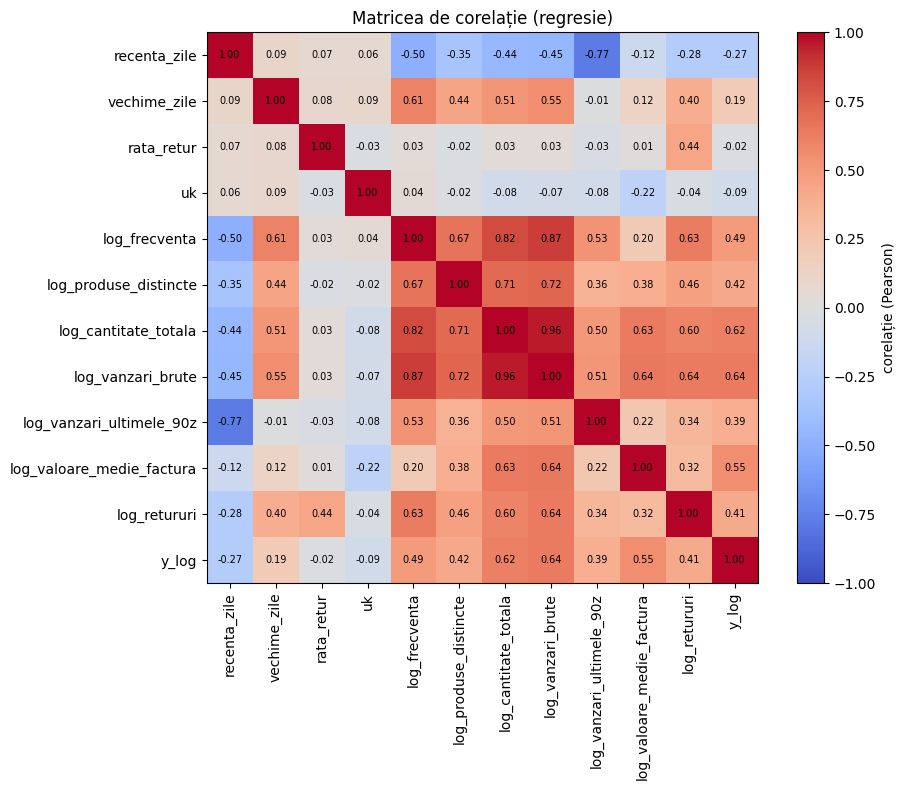

Corelația cu ținta:


log_vanzari_brute            0.640
log_cantitate_totala         0.616
log_valoare_medie_factura    0.553
log_frecventa                0.491
log_produse_distincte        0.420
log_retururi                 0.410
log_vanzari_ultimele_90z     0.387
vechime_zile                 0.189
rata_retur                  -0.020
uk                          -0.092
recenta_zile                -0.274
Name: y_log, dtype: float64

,VIF_toate,VIF_final
log_vanzari_brute,233.632,NaN
log_frecventa,125.961,4.959
log_valoare_medie_factura,54.442,1.371
log_cantitate_totala,12.101,NaN
recenta_zile,3.553,3.042
log_vanzari_ultimele_90z,3.003,2.863
vechime_zile,2.820,2.469
log_retururi,2.570,2.541
log_produse_distincte,2.208,2.101
rata_retur,1.469,1.457


Variabile finale: ['recenta_zile', 'vechime_zile', 'rata_retur', 'uk', 'log_frecventa', 'log_produse_distincte', 'log_vanzari_ultimele_90z', 'log_valoare_medie_factura', 'log_retururi']
VIF maxim după eliminare: 5.0 (ok, sub 10)


In [9]:
y_log_reg = np.log1p(clienti_reg["tinta_cheltuiala"]).rename("y_log")
corelatie = pd.concat([X_toate.loc[clienti_reg.index], y_log_reg], axis=1).corr()
corelatie.to_csv(ARTEFACTE / "corelatie.csv")

plt.figure(figsize=(10, 8))
plt.imshow(corelatie, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="corelație (Pearson)")
plt.xticks(range(len(corelatie)), corelatie.columns, rotation=90)
plt.yticks(range(len(corelatie)), corelatie.columns)
for i in range(len(corelatie)):
    for j in range(len(corelatie)):
        plt.text(j, i, f"{corelatie.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Matricea de corelație (regresie)")
plt.tight_layout()
salveaza_fig("corelatie")

print("Corelația cu ținta:")
display(corelatie["y_log"].drop("y_log").sort_values(ascending=False))


def vif(Xdf):
    Xs = pd.DataFrame(StandardScaler().fit_transform(Xdf), columns=Xdf.columns)
    valori = {}
    for c in Xs.columns:
        rest = Xs.drop(columns=c)
        valori[c] = 1 / (1 - LinearRegression().fit(rest, Xs[c]).score(rest, Xs[c]))
    return pd.Series(valori, name="VIF").sort_values(ascending=False)


REDUNDANTE = ["log_vanzari_brute", "log_cantitate_totala"]
FEATURI = [c for c in X_toate.columns if c not in REDUNDANTE]
vif_inainte = vif(X_toate.loc[clienti_reg.index])
vif_dupa = vif(X_toate.loc[clienti_reg.index, FEATURI])
vif_tabel = pd.concat([vif_inainte.rename("VIF_toate"), vif_dupa.rename("VIF_final")], axis=1)
vif_tabel.to_csv(ARTEFACTE / "vif.csv")
display(vif_tabel)
print("Variabile finale:", FEATURI)
print(f"VIF maxim după eliminare: {vif_dupa.max():.1f}", "(ok, sub 10)" if vif_dupa.max() < 10 else "(ATENȚIE: încă peste 10, reia selecția)")

---
## 4. LABORATOR 1 · REGRESIA (multifactorială)
### 4.1 Împărțire train/test și baza de comparație
80% train / 20% test (clienții au aceeași dată de tăiere, deci o împărțire aleatorie nu scurge informație; limită: nu testăm alte perioade ale anului).
Metrici: **R², R² ajustat, MAE, MSE, RMSE, MAPE**, calculate în log și în lire (`expm1`); MAPE doar în lire.
`DummyRegressor` (media) e baza: orice model util trebuie s-o bată.

In [10]:
X_reg = X_toate.loc[clienti_reg.index, FEATURI]
y_reg = np.log1p(clienti_reg["tinta_cheltuiala"])
X_tr, X_te, y_tr, y_te = train_test_split(X_reg, y_reg, test_size=0.2, random_state=SEED)
print("Train:", X_tr.shape, "| Test:", X_te.shape)


def metrici_reg(model, nume):
    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    n, p = X_te.shape
    r2 = r2_score(y_te, p_te)
    real, prog = np.expm1(y_te), np.expm1(p_te)
    return {"Model": nume, "R2_train": r2_score(y_tr, p_tr), "R2_test": r2,
            "R2_ajustat": 1 - (1 - r2) * (n - 1) / (n - p - 1),
            "MAE_log": mean_absolute_error(y_te, p_te), "MSE_log": mean_squared_error(y_te, p_te),
            "RMSE_log": np.sqrt(mean_squared_error(y_te, p_te)),
            "MAE_£": mean_absolute_error(real, prog), "RMSE_£": np.sqrt(mean_squared_error(real, prog)),
            "MAPE_%": mean_absolute_percentage_error(real, prog) * 100}


cv5 = KFold(n_splits=5, shuffle=True, random_state=SEED)


def cv_reg(model):
    sc = cross_validate(model, X_tr, y_tr, cv=cv5, scoring=("r2", "neg_root_mean_squared_error"), n_jobs=-1)
    return {"R2_cv": sc["test_r2"].mean(), "R2_cv_std": sc["test_r2"].std(),
            "RMSE_log_cv": -sc["test_neg_root_mean_squared_error"].mean()}


baza_reg = DummyRegressor(strategy="mean").fit(X_tr, y_tr)
display(pd.DataFrame([metrici_reg(baza_reg, "Baza (media)")]).set_index("Model"))

Train: (1824, 9) | Test: (457, 9)


,R2_train,R2_test,R2_ajustat,MAE_log,MSE_log,RMSE_log,MAE_£,RMSE_£,MAPE_%
Model,,,,,,,,,
Baza (media),0.000,-0.004,-0.024,0.794,1.035,1.017,748.230,"2,157.193",103.311


### 4.2 Zece modele (+ gradient descent)
Familii de modele: liniare (Linear, **Ridge** L2, **Lasso** L1, ElasticNet; λ ales prin validare încrucișată), gradient descent (SGD), arbori și ansambluri (Decision Tree, Random Forest, Gradient Boosting, HistGB, XGBoost), KNN.
`StandardScaler` e în `Pipeline` pentru toate (obligatoriu la Ridge/Lasso/KNN/SGD; scalarea se învață doar pe train → fără scurgere).
Pentru fiecare model: metrici pe test (`train` vs `test` arată supraantrenarea) + validare încrucișată 5-fold pe train.

In [11]:
modele_reg = {
    "Regresie liniară":       LinearRegression(),
    "Ridge (CV)":             RidgeCV(alphas=np.logspace(-3, 3, 50)),
    "Lasso (CV)":             LassoCV(cv=5, random_state=SEED, max_iter=10000),
    "ElasticNet (CV)":        ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], cv=5, random_state=SEED, max_iter=10000),
    "Gradient descent (SGD)": SGDRegressor(max_iter=5000, tol=1e-4, eta0=0.01, random_state=SEED),
    "Arbore de decizie":      DecisionTreeRegressor(max_depth=5, random_state=SEED),
    "Random Forest":          RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=1),
    "Gradient Boosting":      GradientBoostingRegressor(random_state=SEED),
    "HistGradientBoosting":   HistGradientBoostingRegressor(random_state=SEED),
    "KNN (k=5)":              KNeighborsRegressor(n_neighbors=5),
    "XGBoost":                XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED, n_jobs=1),
}

antrenate_reg, rez = {}, []
for nume, model in modele_reg.items():
    pipe = Pipeline([("scalare", StandardScaler()), ("model", clone(model))]).fit(X_tr, y_tr)
    antrenate_reg[nume] = pipe
    rez.append({**metrici_reg(pipe, nume), **cv_reg(clone(pipe))})

tabel_reg = pd.DataFrame(rez).set_index("Model").sort_values("RMSE_log_cv")
display(tabel_reg)

,R2_train,R2_test,R2_ajustat,MAE_log,MSE_log,RMSE_log,MAE_£,RMSE_£,MAPE_%,R2_cv,R2_cv_std,RMSE_log_cv
Model,,,,,,,,,,,,
Lasso (CV),0.485,0.511,0.501,0.546,0.504,0.710,503.788,"1,376.333",67.932,0.478,0.072,0.792
Regresie liniară,0.485,0.511,0.501,0.546,0.505,0.710,501.325,"1,362.123",67.990,0.478,0.073,0.792
ElasticNet (CV),0.485,0.511,0.501,0.546,0.505,0.710,504.760,"1,380.747",67.961,0.478,0.072,0.792
Ridge (CV),0.485,0.510,0.501,0.546,0.505,0.711,502.563,"1,369.657",67.987,0.478,0.072,0.792
Gradient descent (SGD),0.485,0.512,0.502,0.546,0.504,0.710,506.231,"1,392.116",68.299,0.477,0.072,0.793
Gradient Boosting,0.645,0.490,0.480,0.564,0.526,0.725,526.847,"1,257.502",70.770,0.461,0.054,0.806
Random Forest,0.826,0.489,0.478,0.564,0.527,0.726,561.496,"1,514.068",70.747,0.459,0.050,0.807
XGBoost,0.755,0.465,0.454,0.579,0.552,0.743,560.047,"1,449.781",72.619,0.435,0.054,0.825
HistGradientBoosting,0.812,0.451,0.440,0.582,0.567,0.753,585.432,"1,582.045",75.648,0.422,0.064,0.835


### 4.3 Coeficienți: liniar vs Ridge vs Lasso, și traiectoria Lasso
Ridge micșorează coeficienții, **Lasso poate pune coeficienți exact 0** (selecție de variabile). Variabilele sunt standardizate, deci coeficienții se pot compara.
Traiectoria arată ordinea în care Lasso renunță la variabile când penalizarea λ crește (cele rezistente = cele mai importante).

λ Ridge: 4.714866363457395 | λ Lasso: 0.0016049430279322149
Coeficienți Lasso exact 0: []


,Regresie liniară,Ridge (CV),Lasso (CV)
recenta_zile,0.1911,0.1870,0.1806
vechime_zile,-0.2347,-0.2299,-0.2269
rata_retur,-0.0789,-0.0792,-0.0753
uk,-0.0021,-0.0023,-0.0006
log_frecventa,0.5736,0.5646,0.5622
log_produse_distincte,-0.0402,-0.0377,-0.0345
log_vanzari_ultimele_90z,0.1307,0.1310,0.1266
log_valoare_medie_factura,0.5010,0.4989,0.4993
log_retururi,0.0975,0.0994,0.0948


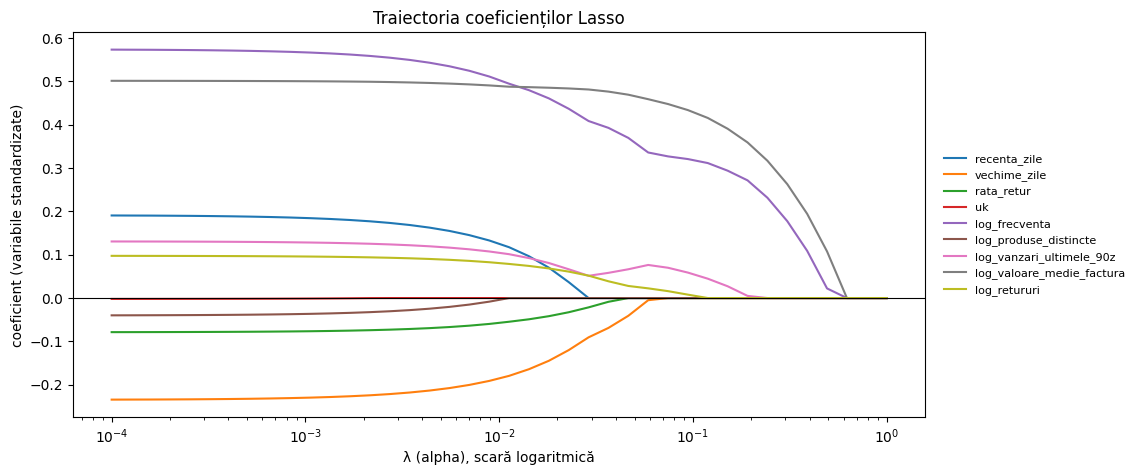

In [12]:
coef = pd.DataFrame({n: antrenate_reg[n].named_steps["model"].coef_ for n in ["Regresie liniară", "Ridge (CV)", "Lasso (CV)"]},
                    index=FEATURI)
coef.to_csv(ARTEFACTE / "coeficienti_regresie.csv")
print("λ Ridge:", antrenate_reg["Ridge (CV)"].named_steps["model"].alpha_,
      "| λ Lasso:", antrenate_reg["Lasso (CV)"].named_steps["model"].alpha_)
print("Coeficienți Lasso exact 0:", [f for f, c in zip(FEATURI, coef["Lasso (CV)"]) if c == 0])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(coef)

alfe_l = np.logspace(-4, 0, 40)
Xs = StandardScaler().fit(X_tr).transform(X_tr)
traiect = pd.DataFrame([Lasso(alpha=a, max_iter=10000).fit(Xs, y_tr).coef_ for a in alfe_l], index=alfe_l, columns=FEATURI)
ax = traiect.plot(logx=True, figsize=(11, 5))
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8, frameon=False)          # legenda în afara graficului: nu acoperă curbele
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("λ (alpha), scară logaritmică"); ax.set_ylabel("coeficient (variabile standardizate)")
ax.set_title("Traiectoria coeficienților Lasso")
salveaza_fig("lasso_traiectorie")

### 4.4 Reglaj fin (hyperparameter tuning)
Modelele cu arbori supraantrenează (R² train ≫ R² test). `RandomizedSearchCV` încearcă `n_iter` combinații aleatoare, fiecare evaluată prin validare încrucișată, și caută arbori mai simpli (adâncime mică, frunze mari, învățare lentă).

In [13]:
cautari_reg = {
    "Random Forest (reglat)": RandomizedSearchCV(
        RandomForestRegressor(random_state=SEED, n_jobs=1),
        {"n_estimators": [200, 400], "max_depth": [3, 5, 8], "min_samples_leaf": [3, 5, 10, 20], "max_features": [0.5, 0.8, 1.0]},
        n_iter=20, cv=cv5, scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=-1),
    "Gradient Boosting (reglat)": RandomizedSearchCV(
        GradientBoostingRegressor(random_state=SEED),
        {"n_estimators": [100, 200, 400], "learning_rate": [0.01, 0.03, 0.05, 0.1], "max_depth": [2, 3, 4],
         "min_samples_leaf": [5, 10, 20], "subsample": [0.6, 0.8, 1.0]},
        n_iter=25, cv=cv5, scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=-1),
}
for nume, cautare in cautari_reg.items():
    cautare.fit(X_tr, y_tr)
    print(f"{nume} | RMSE_log (cv): {-cautare.best_score_:.3f} | {cautare.best_params_}")

Random Forest (reglat) | RMSE_log (cv): 0.790 | {'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.8, 'max_depth': 5}


Gradient Boosting (reglat) | RMSE_log (cv): 0.786 | {'subsample': 0.6, 'n_estimators': 200, 'min_samples_leaf': 10, 'max_depth': 2, 'learning_rate': 0.03}


### 4.5 Finaliști și ansambluri
Un ansamblu ajută doar dacă modelele greșesc în locuri diferite → verificăm **corelația predicțiilor**.
Finaliști (câte unul pe familie): **Ridge** (liniar), **Random Forest** (bagging), **Gradient Boosting** (boosting).
Ansambluri: **media** predicțiilor, **media ponderată** (pondere ∝ 1/RMSE din CV: modelele mai bune cântăresc mai mult), **stacking** (meta-model Ridge peste predicțiile modelelor de bază, cu k-fold).

In [14]:
ridge_p = antrenate_reg["Ridge (CV)"]
rf_t = cautari_reg["Random Forest (reglat)"].best_estimator_
gb_t = cautari_reg["Gradient Boosting (reglat)"].best_estimator_
finalisti_reg = {"Ridge": ridge_p, "Random Forest (reglat)": rf_t, "Gradient Boosting (reglat)": gb_t}

pred_te_reg = pd.DataFrame({n: m.predict(X_te) for n, m in finalisti_reg.items()})
corel_pred_reg = pred_te_reg.corr()
corel_pred_reg.to_csv(ARTEFACTE / "corelatie_predictii_regresie.csv")
print("Corelația predicțiilor pe test (aproape de 1 = modele aproape identice):")
display(corel_pred_reg)

rmse_cv = np.array([tabel_reg.loc["Ridge (CV)", "RMSE_log_cv"],
                    -cautari_reg["Random Forest (reglat)"].best_score_,
                    -cautari_reg["Gradient Boosting (reglat)"].best_score_])
pesi = (1 / rmse_cv) / (1 / rmse_cv).sum()
print("Ponderi ansamblu:", {n: round(float(p), 3) for n, p in zip(finalisti_reg, pesi)})

baza_est = [("ridge", clone(ridge_p)), ("rf", clone(rf_t)), ("gb", clone(gb_t))]
ansambluri_reg = {
    "Ansamblu: medie":            VotingRegressor(baza_est),
    "Ansamblu: medie ponderată":  VotingRegressor(baza_est, weights=list(pesi)),
    "Ansamblu: stacking":         StackingRegressor(baza_est, final_estimator=RidgeCV(), cv=5),
}
candidati_reg = {**finalisti_reg}
for nume, ens in ansambluri_reg.items():
    candidati_reg[nume] = ens.fit(X_tr, y_tr)

Corelația predicțiilor pe test (aproape de 1 = modele aproape identice):


,Ridge,Random Forest (reglat),Gradient Boosting (reglat)
Ridge,1.000,0.933,0.942
Random Forest (reglat),0.933,1.000,0.988
Gradient Boosting (reglat),0.942,0.988,1.000


Ponderi ansamblu: {'Ridge': 0.332, 'Random Forest (reglat)': 0.333, 'Gradient Boosting (reglat)': 0.335}


### 4.6 Evaluare finală (regresie)
Alegem modelul de implementat după **RMSE din validare încrucișată** (nu după test, ca testul să rămână o estimare neutră).
Raportăm: R² cv ± std, R² test, MAE/RMSE/MAPE. `expm1` al unei predicții în log estimează mai degrabă mediana decât media → erorile în lire sunt ușor părtinitoare, dar comparabile între modele.

,R2_train,R2_test,R2_ajustat,MAE_log,MSE_log,RMSE_log,MAE_£,RMSE_£,MAPE_%,R2_cv,R2_cv_std,RMSE_log_cv
Model,,,,,,,,,,,,
Ansamblu: medie,0.546,0.518,0.508,0.549,0.497,0.705,499.021,"1,123.757",68.745,0.497,0.062,0.778
Ansamblu: medie ponderată,0.546,0.518,0.508,0.549,0.497,0.705,499.014,"1,123.413",68.751,0.497,0.062,0.778
Ansamblu: stacking,0.544,0.519,0.509,0.546,0.496,0.704,498.179,"1,145.658",68.510,0.496,0.065,0.778
Gradient Boosting (reglat),0.546,0.498,0.488,0.560,0.518,0.719,535.502,"1,348.463",71.171,0.486,0.063,0.786
Random Forest (reglat),0.566,0.494,0.483,0.566,0.522,0.723,588.743,"1,560.662",71.450,0.482,0.051,0.790
Ridge,0.485,0.510,0.501,0.546,0.505,0.711,502.563,"1,369.657",67.987,0.478,0.072,0.792


Model ales pentru implementare (RMSE cv minim): Ansamblu: medie


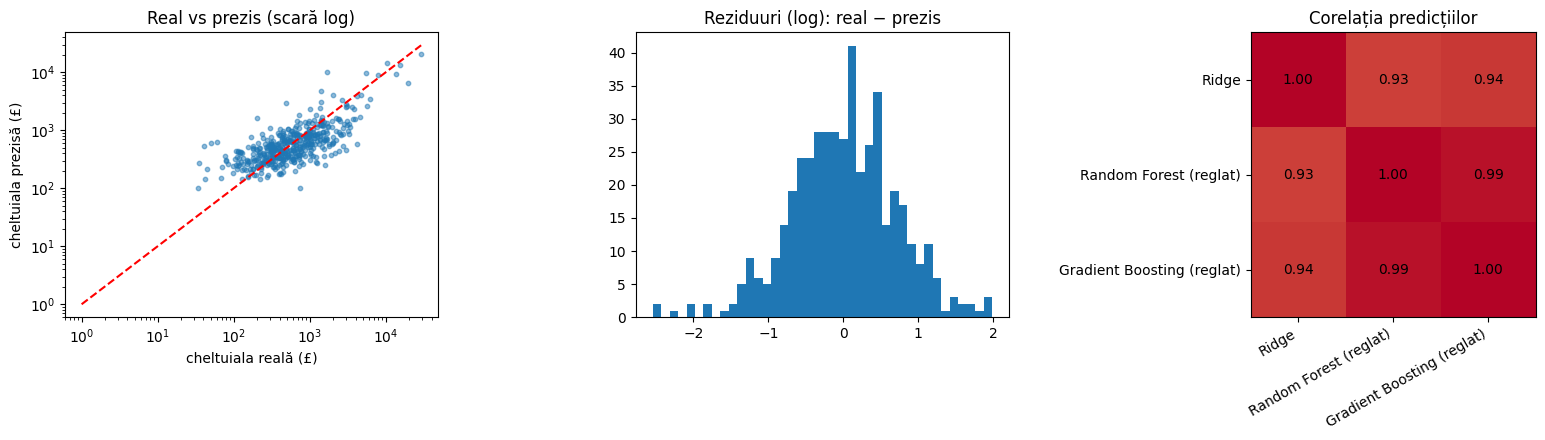

In [15]:
rez = []
for nume, m in candidati_reg.items():
    rez.append({**metrici_reg(m, nume), **cv_reg(clone(m))})
tabel_final_reg = pd.DataFrame(rez).set_index("Model").sort_values("RMSE_log_cv")
tabel_reg.to_csv(ARTEFACTE / "metrici_regresie_10_modele.csv")
tabel_final_reg.to_csv(ARTEFACTE / "metrici_regresie_finalisti.csv")
display(tabel_final_reg)

nume_best_reg = tabel_final_reg.index[0]
model_reg = candidati_reg[nume_best_reg]
print("Model ales pentru implementare (RMSE cv minim):", nume_best_reg)

p_te = model_reg.predict(X_te)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(np.expm1(y_te), np.expm1(p_te), s=10, alpha=0.5)
lim = [1, max(np.expm1(y_te).max(), np.expm1(p_te).max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("cheltuiala reală (£)"); ax[0].set_ylabel("cheltuiala prezisă (£)"); ax[0].set_title("Real vs prezis (scară log)")
ax[1].hist(y_te - p_te, bins=40); ax[1].set_title("Reziduuri (log): real − prezis")
ax[2].imshow(corel_pred_reg, cmap="coolwarm", vmin=0, vmax=1)
ax[2].set_xticks(range(3)); ax[2].set_xticklabels(corel_pred_reg.columns, rotation=30, ha="right")
ax[2].set_yticks(range(3)); ax[2].set_yticklabels(corel_pred_reg.index)
for i in range(3):
    for j in range(3):
        ax[2].text(j, i, f"{corel_pred_reg.iloc[i, j]:.2f}", ha="center", va="center")
ax[2].set_title("Corelația predicțiilor")
plt.tight_layout()
salveaza_fig("regresie_diagnostic")

pd.DataFrame({"real_£": np.expm1(y_te), "prezis_£": np.expm1(p_te)}, index=y_te.index).to_csv(ARTEFACTE / "predictii_test_regresie.csv")

---
## 5. LABORATOR 2 · CLASIFICAREA (binară)
### 5.1 Eticheta, balansul claselor și împărțirea
Eticheta: `a_cumparat` (1 = a avut cel puțin o vânzare în ultimele 90 de zile). Aceleași variabile ca la regresie.
Verificăm **balansul claselor** (clasele dezechilibrate cer atenție la metrică: SMOTE sau curba precision-recall); împărțire **stratificată** (aceeași proporție de clase în train și test).

In [16]:
X_c = X_toate[FEATURI]
y_c = clienti["a_cumparat"].astype(int)
balans = y_c.value_counts().rename({0: "nu cumpără (0)", 1: "cumpără (1)"}).to_frame("clienți")
balans["%"] = (balans["clienți"] / len(y_c) * 100).round(1)
display(balans)
balans.to_csv(ARTEFACTE / "balans_clase.csv")
print("Clasele sunt aproximativ echilibrate → nu e nevoie de SMOTE; contează metricile precision/recall/F1/AUC, nu doar accuracy.")

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_c, y_c, test_size=0.2, stratify=y_c, random_state=SEED)
print("Train:", Xc_tr.shape, "| Test:", Xc_te.shape)

,clienți,%
a_cumparat,,
nu cumpără (0),2967,56.400
cumpără (1),2289,43.600


Clasele sunt aproximativ echilibrate → nu e nevoie de SMOTE; contează metricile precision/recall/F1/AUC, nu doar accuracy.
Train: (4204, 9) | Test: (1052, 9)


**Metrici:** matrice de confuzie (TP, TN, FP = eroare tip I, FN = eroare tip II), accuracy, precision, recall, F1, **ROC-AUC** (0,5 = aleator, 1 = perfect) și **PR-AUC** (curba precision-recall).
Pragul de decizie implicit e 0,5 (modificabil, vezi 5.8).

In [17]:
def metrici_clf(model, nume, prag=0.5):
    if hasattr(model, "predict_proba"):
        pr_te, pr_tr = model.predict_proba(Xc_te)[:, 1], model.predict_proba(Xc_tr)[:, 1]
        pred = (pr_te >= prag).astype(int)
        auc, auc_tr, pr_auc = roc_auc_score(yc_te, pr_te), roc_auc_score(yc_tr, pr_tr), average_precision_score(yc_te, pr_te)
        acc_tr = accuracy_score(yc_tr, (pr_tr >= prag).astype(int))
    else:                                        # hard voting: fără probabilități
        pred = model.predict(Xc_te)
        auc = auc_tr = pr_auc = np.nan
        acc_tr = accuracy_score(yc_tr, model.predict(Xc_tr))
    return {"Model": nume, "Acc_train": acc_tr, "Accuracy": accuracy_score(yc_te, pred),
            "Precision": precision_score(yc_te, pred, zero_division=0), "Recall": recall_score(yc_te, pred),
            "F1": f1_score(yc_te, pred), "ROC_AUC_train": auc_tr, "ROC_AUC": auc, "PR_AUC": pr_auc}


cv5c = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def cv_clf(model):
    sc = cross_validate(model, Xc_tr, yc_tr, cv=cv5c, scoring=("roc_auc", "f1", "accuracy"), n_jobs=-1)
    return {"AUC_cv": sc["test_roc_auc"].mean(), "AUC_cv_std": sc["test_roc_auc"].std(),
            "F1_cv": sc["test_f1"].mean(), "Acc_cv": sc["test_accuracy"].mean()}


baza_clf = DummyClassifier(strategy="prior").fit(Xc_tr, yc_tr)
display(pd.DataFrame([metrici_clf(baza_clf, "Baza (clasa majoritară)")]).set_index("Model"))

,Acc_train,Accuracy,Precision,Recall,F1,ROC_AUC_train,ROC_AUC,PR_AUC
Model,,,,,,,,
Baza (clasa majoritară),0.564,0.565,0.000,0.000,0.000,0.500,0.500,0.435


### 5.2 Alegerea lui K la KNN
Nu există un K ideal: încercăm mai multe valori (un K mic, 1–2, e sensibil la outlieri). Comparăm câteva valori prin AUC în validare încrucișată.

In [18]:
rez_k = []
for k in [3, 5, 7, 11, 15, 21]:
    pipe = Pipeline([("scalare", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=k))])
    rez_k.append({"K": k, "AUC_cv": cross_val_score(pipe, Xc_tr, yc_tr, cv=cv5c, scoring="roc_auc", n_jobs=-1).mean()})
tabel_k = pd.DataFrame(rez_k).set_index("K")
display(tabel_k)
K_BUN = int(tabel_k["AUC_cv"].idxmax())
print("K ales:", K_BUN)

,AUC_cv
K,
3,0.710
5,0.746
7,0.756
11,0.770
15,0.774
21,0.783


K ales: 21


### 5.3 Nouă modele
Regresie logistică, Naive Bayes, KNN, SVM, arbore de decizie, Random Forest, Gradient Boosting, HistGradientBoosting, XGBoost.
Același tipar ca la regresie: `Pipeline` cu scalare, metrici pe test și validare încrucișată pe train.

In [19]:
modele_clf = {
    "Regresie logistică": LogisticRegression(max_iter=2000),
    "Naive Bayes":        GaussianNB(),
    f"KNN (k={K_BUN})":   KNeighborsClassifier(n_neighbors=K_BUN),
    "SVM (RBF)":          SVC(probability=True, random_state=SEED),
    "Arbore de decizie":  DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random Forest":      RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=1),
    "Gradient Boosting":  GradientBoostingClassifier(random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=SEED),
    "XGBoost":            XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, eval_metric="logloss",
                                        random_state=SEED, n_jobs=1),
}
antrenate_clf, rez = {}, []
for nume, model in modele_clf.items():
    pipe = Pipeline([("scalare", StandardScaler()), ("model", clone(model))]).fit(Xc_tr, yc_tr)
    antrenate_clf[nume] = pipe
    rez.append({**metrici_clf(pipe, nume), **cv_clf(clone(pipe))})
tabel_clf = pd.DataFrame(rez).set_index("Model").sort_values("AUC_cv", ascending=False)
display(tabel_clf)

,Acc_train,Accuracy,Precision,Recall,F1,ROC_AUC_train,ROC_AUC,PR_AUC,AUC_cv,AUC_cv_std,F1_cv,Acc_cv
Model,,,,,,,,,,,,
Regresie logistică,0.727,0.749,0.746,0.642,0.690,0.796,0.809,0.789,0.793,0.011,0.669,0.726
Gradient Boosting,0.770,0.743,0.742,0.629,0.681,0.849,0.813,0.794,0.792,0.012,0.656,0.719
XGBoost,0.781,0.745,0.746,0.629,0.682,0.854,0.813,0.794,0.790,0.015,0.655,0.720
Naive Bayes,0.722,0.739,0.707,0.683,0.695,0.789,0.796,0.774,0.788,0.013,0.680,0.719
Random Forest,0.880,0.744,0.748,0.622,0.679,0.955,0.811,0.791,0.787,0.014,0.655,0.716
KNN (k=21),0.739,0.733,0.725,0.622,0.670,0.818,0.792,0.761,0.783,0.014,0.654,0.713
SVM (RBF),0.738,0.747,0.753,0.624,0.683,0.803,0.802,0.769,0.777,0.017,0.661,0.723
HistGradientBoosting,0.880,0.731,0.728,0.609,0.663,0.951,0.793,0.770,0.774,0.013,0.647,0.710
Arbore de decizie,0.720,0.727,0.697,0.659,0.678,0.797,0.799,0.739,0.773,0.009,0.647,0.703


### 5.4 Reglaj fin (hyperparameter tuning)
Căutare aleatoare cu validare încrucișată, optimizând **ROC-AUC**, pentru Random Forest și Gradient Boosting (arbori mai simpli = mai puțină supraantrenare).

In [20]:
cautari_clf = {
    "Random Forest (reglat)": RandomizedSearchCV(
        RandomForestClassifier(random_state=SEED, n_jobs=1),
        {"n_estimators": [200, 400], "max_depth": [3, 5, 8], "min_samples_leaf": [3, 5, 10, 20], "max_features": [0.5, 0.8, "sqrt"]},
        n_iter=20, cv=cv5c, scoring="roc_auc", random_state=SEED, n_jobs=-1),
    "Gradient Boosting (reglat)": RandomizedSearchCV(
        GradientBoostingClassifier(random_state=SEED),
        {"n_estimators": [100, 200, 400], "learning_rate": [0.01, 0.03, 0.05, 0.1], "max_depth": [2, 3, 4],
         "min_samples_leaf": [5, 10, 20], "subsample": [0.6, 0.8, 1.0]},
        n_iter=25, cv=cv5c, scoring="roc_auc", random_state=SEED, n_jobs=-1),
}
for nume, cautare in cautari_clf.items():
    cautare.fit(Xc_tr, yc_tr)
    print(f"{nume} | AUC (cv): {cautare.best_score_:.3f} | {cautare.best_params_}")

Random Forest (reglat) | AUC (cv): 0.794 | {'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 5}


Gradient Boosting (reglat) | AUC (cv): 0.795 | {'subsample': 0.6, 'n_estimators': 100, 'min_samples_leaf': 10, 'max_depth': 4, 'learning_rate': 0.03}


### 5.5 Ansambluri: voting, stacking, bagging, boosting
- **Hard voting:** votul majorității. **Soft voting:** media probabilităților. **Vot ponderat:** modelele mai bune (AUC cv mai mare) cântăresc mai mult.
- **Stacking:** modelele de bază produc predicții, iar un **meta-model** (regresie logistică) le combină; `cv=5` (validare încrucișată *k-folds*) previne supraadaptarea.
- **Bagging:** arbori antrenați pe eșantioane cu înlocuire (în medie 63% din date); celelalte 37% (*out-of-bag*) dau o estimare gratuită a performanței.
- **Boosting:** Gradient Boosting / XGBoost (deja în comparație): modele slabe construite secvențial pe erorile anterioare.
Finaliști (câte unul pe familie): regresie logistică (liniar), SVM (kernel), Random Forest (bagging), Gradient Boosting (boosting).

In [21]:
log_p = antrenate_clf["Regresie logistică"]
svm_p = antrenate_clf["SVM (RBF)"]
rf_c = cautari_clf["Random Forest (reglat)"].best_estimator_
gb_c = cautari_clf["Gradient Boosting (reglat)"].best_estimator_
finalisti_clf = {"Regresie logistică": log_p, "SVM (RBF)": svm_p, "Random Forest (reglat)": rf_c, "Gradient Boosting (reglat)": gb_c}

proba_te = pd.DataFrame({n: m.predict_proba(Xc_te)[:, 1] for n, m in finalisti_clf.items()})
corel_pred_clf = proba_te.corr()
corel_pred_clf.to_csv(ARTEFACTE / "corelatie_predictii_clasificare.csv")
print("Corelația probabilităților prezise (test):")
display(corel_pred_clf)

auc_cv = np.array([tabel_clf.loc["Regresie logistică", "AUC_cv"], tabel_clf.loc["SVM (RBF)", "AUC_cv"],
                   cautari_clf["Random Forest (reglat)"].best_score_, cautari_clf["Gradient Boosting (reglat)"].best_score_])
pesi_c = list(auc_cv / auc_cv.sum())

baza_c = [("log", clone(log_p)), ("svm", clone(svm_p)), ("rf", clone(rf_c)), ("gb", clone(gb_c))]
bagging = BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=4), n_estimators=100, oob_score=True,
                            random_state=SEED, n_jobs=1)
ansambluri_clf = {
    "Voting hard":              VotingClassifier(baza_c, voting="hard"),
    "Voting soft":              VotingClassifier(baza_c, voting="soft"),
    "Voting soft ponderat":     VotingClassifier(baza_c, voting="soft", weights=pesi_c),
    "Stacking (meta: logistică)": StackingClassifier(baza_c, final_estimator=LogisticRegression(max_iter=2000), cv=5,
                                                      stack_method="predict_proba"),
    "Bagging (arbori)":         bagging,
}
candidati_clf = dict(finalisti_clf)
for nume, ens in ansambluri_clf.items():
    candidati_clf[nume] = ens.fit(Xc_tr, yc_tr)
print(f"Bagging: acuratețe out-of-bag = {bagging.oob_score_:.3f}")

Corelația probabilităților prezise (test):


,Regresie logistică,SVM (RBF),Random Forest (reglat),Gradient Boosting (reglat)
Regresie logistică,1.000,0.921,0.975,0.969
SVM (RBF),0.921,1.000,0.916,0.927
Random Forest (reglat),0.975,0.916,1.000,0.987
Gradient Boosting (reglat),0.969,0.927,0.987,1.000


Bagging: acuratețe out-of-bag = 0.720


### 5.6 Evaluare finală (clasificare)
Alegem modelul de implementat după **AUC din validare încrucișată** (doar modele cu probabilități), iar testul rămâne estimare neutră.
Tabelul arată toate metricile, pentru toți candidații.

In [22]:
rez = []
for nume, m in candidati_clf.items():
    cv_m = cv_clf(clone(m)) if nume != "Voting hard" else {}
    rez.append({**metrici_clf(m, nume), **cv_m})
tabel_final_clf = pd.DataFrame(rez).set_index("Model").sort_values("AUC_cv", ascending=False)
tabel_clf.to_csv(ARTEFACTE / "metrici_clasificare_9_modele.csv")
tabel_final_clf.to_csv(ARTEFACTE / "metrici_clasificare_finalisti.csv")
display(tabel_final_clf)

nume_best_clf = tabel_final_clf["AUC_cv"].dropna().index[0]
model_clf = candidati_clf[nume_best_clf]
print("Model ales pentru implementare (AUC cv maxim):", nume_best_clf)

,Acc_train,Accuracy,Precision,Recall,F1,ROC_AUC_train,ROC_AUC,PR_AUC,AUC_cv,AUC_cv_std,F1_cv,Acc_cv
Model,,,,,,,,,,,,
Voting soft,0.743,0.755,0.765,0.631,0.691,0.820,0.816,0.795,0.797,0.013,0.664,0.724
Voting soft ponderat,0.743,0.755,0.765,0.631,0.691,0.820,0.816,0.795,0.797,0.013,0.664,0.724
Stacking (meta: logistică),0.749,0.758,0.757,0.653,0.701,0.822,0.816,0.795,0.796,0.012,0.668,0.725
Gradient Boosting (reglat),0.764,0.752,0.763,0.624,0.687,0.837,0.818,0.796,0.795,0.014,0.659,0.723
Random Forest (reglat),0.748,0.753,0.761,0.631,0.690,0.820,0.815,0.794,0.794,0.012,0.662,0.723
Regresie logistică,0.727,0.749,0.746,0.642,0.690,0.796,0.809,0.789,0.793,0.011,0.669,0.726
Bagging (arbori),0.739,0.750,0.753,0.633,0.688,0.815,0.815,0.791,0.792,0.011,0.655,0.715
SVM (RBF),0.738,0.747,0.753,0.624,0.683,0.803,0.802,0.769,0.777,0.017,0.661,0.723
Voting hard,0.752,0.749,0.771,0.603,0.676,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Model ales pentru implementare (AUC cv maxim): Voting soft


### 5.7 Matrice de confuzie, curba ROC și curba precision-recall
**Matricea de confuzie** (prag 0,5): TP, TN, FP (tip I), FN (tip II). **ROC:** TPR vs FPR la toate pragurile (AUC mare = deosebește bine clasele). **Precision-Recall:** arată compromisul între precizie și recall (utilă și la clase dezechilibrate).

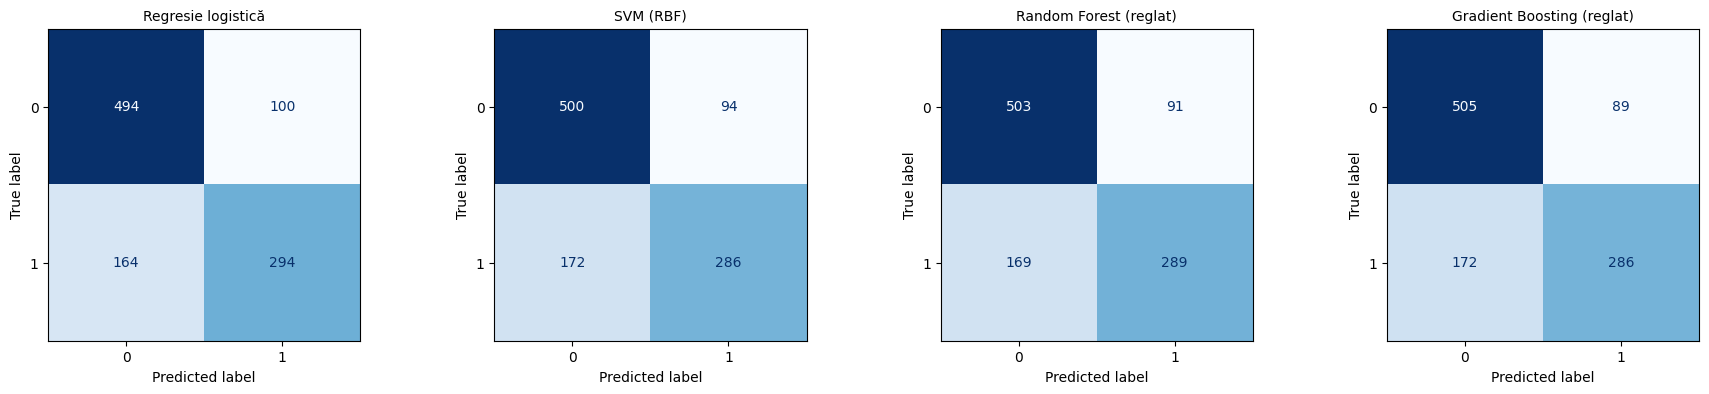

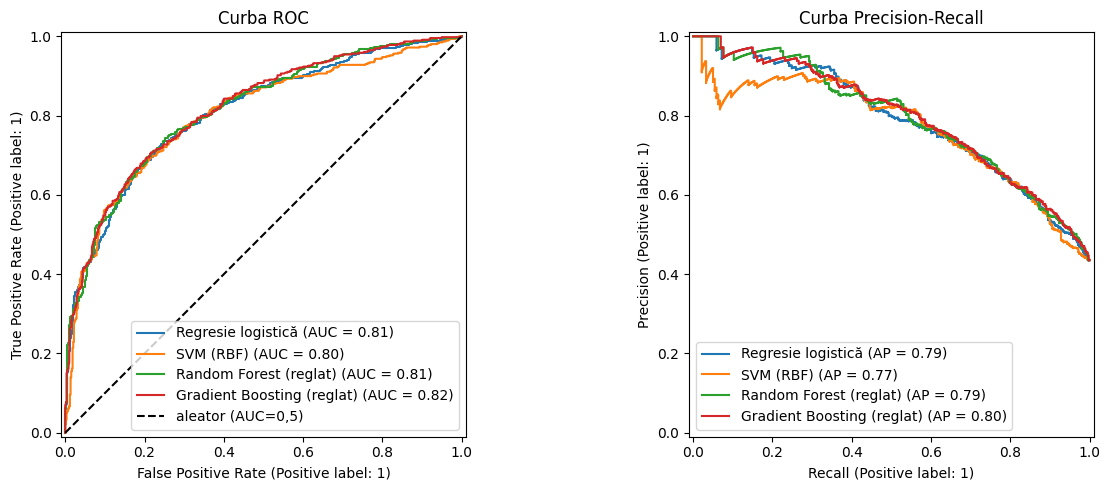

In [23]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, (nume, m) in zip(ax, finalisti_clf.items()):
    ConfusionMatrixDisplay.from_predictions(yc_te, m.predict(Xc_te), ax=a, colorbar=False, cmap="Blues")
    a.set_title(nume, fontsize=10)
plt.tight_layout()
salveaza_fig("clasificare_matrici_confuzie")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nume, m in finalisti_clf.items():
    pr = m.predict_proba(Xc_te)[:, 1]
    RocCurveDisplay.from_predictions(yc_te, pr, name=nume, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(yc_te, pr, name=nume, ax=ax[1])
ax[0].plot([0, 1], [0, 1], "k--", label="aleator (AUC=0,5)"); ax[0].set_title("Curba ROC"); ax[0].legend()
ax[1].set_title("Curba Precision-Recall")
plt.tight_layout()
salveaza_fig("clasificare_roc_pr")

### 5.8 Alegerea pragului de decizie
Pragul 0,5 nu e obligatoriu. Îl alegem pe **train**, prin predicții din validare încrucișată (nu pe test), la punctul de pe curba ROC cel mai departe de diagonala „aleator” (**indicele Youden**: recall + specificitate − 1). Apoi comparăm pe test 0,5 vs pragul ales.
De ce nu maxim F1? La clase echilibrate, F1 al clasei pozitive e maxim când prezicem „1” pentru toți (prag foarte mic), ceea ce nu e util.
Dacă FN (clienți pierduți neobservați) costă mai mult decât FP, pragul se coboară; dacă FP costă mai mult, se urcă.

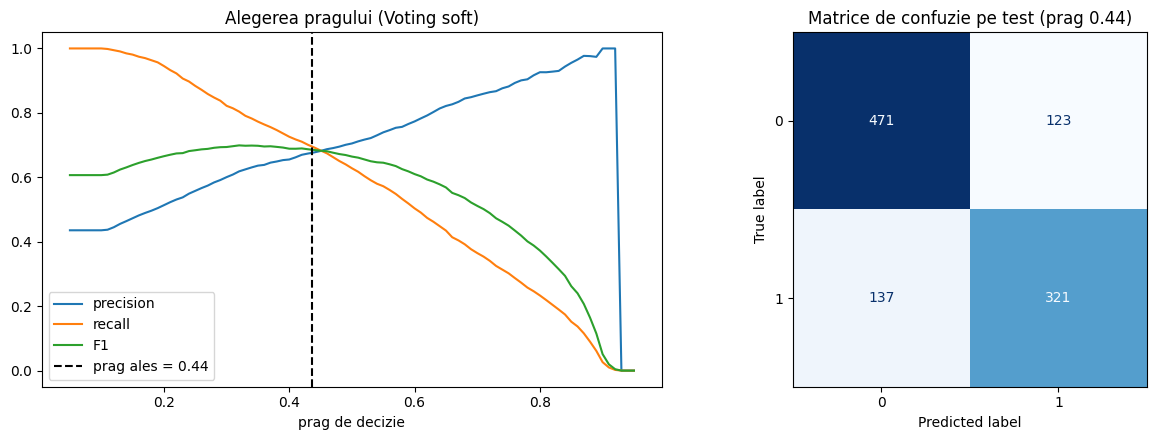

,Accuracy,Precision,Recall,F1
Model,,,,
"prag 0,50",0.755,0.765,0.631,0.691
prag 0.44,0.753,0.723,0.701,0.712


In [24]:
pr_cv = cross_val_predict(clone(model_clf), Xc_tr, yc_tr, cv=cv5c, method="predict_proba")[:, 1]
fpr, tpr, thr = roc_curve(yc_tr, pr_cv)
PRAG = float(np.clip(thr[np.argmax(tpr - fpr)], 0.01, 0.99))
praguri = np.linspace(0.05, 0.95, 91)
curba = pd.DataFrame({
    "prag": praguri,
    "precision": [precision_score(yc_tr, pr_cv >= t, zero_division=0) for t in praguri],
    "recall": [recall_score(yc_tr, pr_cv >= t) for t in praguri],
    "F1": [f1_score(yc_tr, pr_cv >= t) for t in praguri],
})
curba.to_csv(ARTEFACTE / "prag_curba.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(curba["prag"], curba["precision"], label="precision")
ax[0].plot(curba["prag"], curba["recall"], label="recall")
ax[0].plot(curba["prag"], curba["F1"], label="F1")
ax[0].axvline(PRAG, color="k", ls="--", label=f"prag ales = {PRAG:.2f}")
ax[0].set_xlabel("prag de decizie"); ax[0].set_title(f"Alegerea pragului ({nume_best_clf})"); ax[0].legend()
pr_te_best = model_clf.predict_proba(Xc_te)[:, 1]
ConfusionMatrixDisplay.from_predictions(yc_te, (pr_te_best >= PRAG).astype(int), ax=ax[1], colorbar=False, cmap="Blues")
ax[1].set_title(f"Matrice de confuzie pe test (prag {PRAG:.2f})")
plt.tight_layout()
salveaza_fig("clasificare_prag")

comparatie_prag = pd.DataFrame([metrici_clf(model_clf, "prag 0,50", 0.5), metrici_clf(model_clf, f"prag {PRAG:.2f}", PRAG)]).set_index("Model")
comparatie_prag.to_csv(ARTEFACTE / "prag_comparatie.csv")
display(comparatie_prag[["Accuracy", "Precision", "Recall", "F1"]])

### 5.9 Ce contează în model
Coeficienții regresiei logistice (standardizați) arată direcția și mărimea efectului; importanța din Random Forest arată ce variabile folosesc arborii.

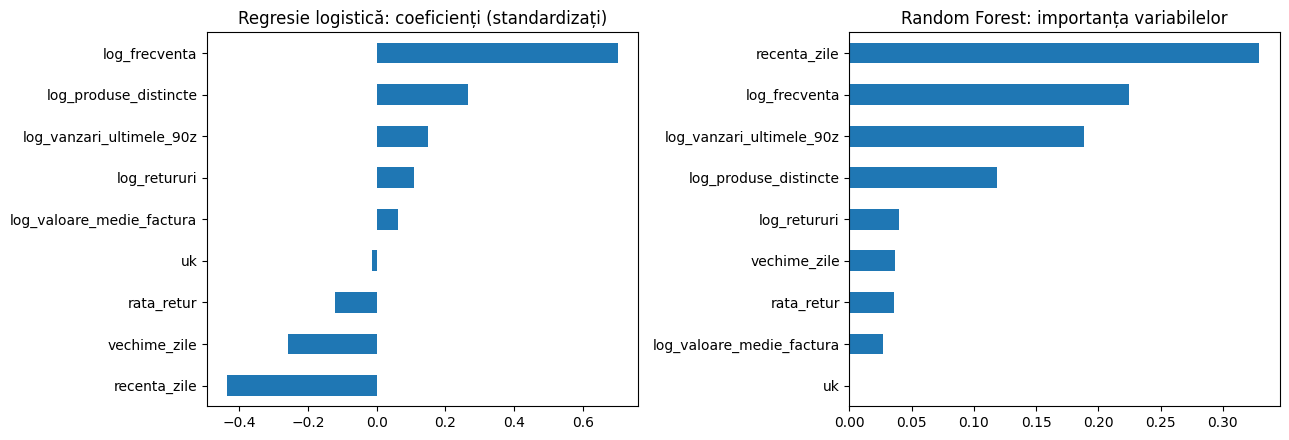

,coef_logistica,importanta_RF
recenta_zile,-0.437,0.330
log_frecventa,0.702,0.224
log_vanzari_ultimele_90z,0.148,0.189
log_produse_distincte,0.266,0.118
log_retururi,0.109,0.040
vechime_zile,-0.259,0.036
rata_retur,-0.120,0.036
log_valoare_medie_factura,0.062,0.027
uk,-0.012,0.000


In [25]:
imp = pd.DataFrame({
    "coef_logistica": log_p.named_steps["model"].coef_[0],
    "importanta_RF": rf_c.feature_importances_,
}, index=FEATURI).sort_values("importanta_RF", ascending=False)
imp.to_csv(ARTEFACTE / "importanta_variabile_clasificare.csv")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
imp["coef_logistica"].sort_values().plot.barh(ax=ax[0]); ax[0].set_title("Regresie logistică: coeficienți (standardizați)")
imp["importanta_RF"].sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Random Forest: importanța variabilelor")
plt.tight_layout()
salveaza_fig("clasificare_importanta")
display(imp)

---
## 6. Implementare (Deployment)
Salvăm tot ce are nevoie aplicația de pe localhost (`streamlit run app.py`): modelele (`joblib`), tabelele de metrici, figurile și un fișier `info.json` cu parametrii proiectului.
Aplicația doar *citește* aceste artefacte, deci laboratoarele următoare adaugă pagini fără să strice ce există.
Modelele salvate sunt cele antrenate pe train (aceleași pe care s-au calculat metricile).

In [26]:
joblib.dump(model_reg, ARTEFACTE / "model_regresie.joblib")
joblib.dump(model_clf, ARTEFACTE / "model_clasificare.joblib")

info = {
    "dataset": "Online Retail II (UCI)",
    "randuri_brute": int(len(df)), "randuri_curate": int(len(tranzactii)),
    "clienti": int(len(clienti)), "clienti_regresie": int(len(clienti_reg)),
    "data_taiere": str(CUTOFF.date()), "sfarsit_date": str(FINAL.date()), "zile_fereastra": ZILE_FEREASTRA,
    "features": FEATURI, "redundante_scoase": REDUNDANTE,
    "regresie": {"model": nume_best_reg, "rmse_log_cv": float(tabel_final_reg.loc[nume_best_reg, "RMSE_log_cv"]),
                 "r2_test": float(tabel_final_reg.loc[nume_best_reg, "R2_test"]),
                 "mae_lire": float(tabel_final_reg.loc[nume_best_reg, "MAE_£"]),
                 "mape": float(tabel_final_reg.loc[nume_best_reg, "MAPE_%"]),
                 "r2_cv": float(tabel_final_reg.loc[nume_best_reg, "R2_cv"]), "rmse_lire": float(tabel_final_reg.loc[nume_best_reg, "RMSE_£"]),
                 "r2_train": float(tabel_final_reg.loc[nume_best_reg, "R2_train"])},
    "clasificare": {"model": nume_best_clf, "auc_cv": float(tabel_final_clf.loc[nume_best_clf, "AUC_cv"]),
                    "auc_test": float(tabel_final_clf.loc[nume_best_clf, "ROC_AUC"]),
                    "f1_test": float(tabel_final_clf.loc[nume_best_clf, "F1"]), "prag": PRAG,
                    "precision": float(tabel_final_clf.loc[nume_best_clf, "Precision"]), "recall": float(tabel_final_clf.loc[nume_best_clf, "Recall"]),
                    "accuracy": float(tabel_final_clf.loc[nume_best_clf, "Accuracy"]),
                    "k_knn": K_BUN, "pondere_clasa_1": float(y_c.mean())},
    "mediane_clienti": clienti.loc[clienti_reg.index, ["recenta_zile", "vechime_zile", "frecventa", "produse_distincte",
                                                        "vanzari_ultimele_90z", "valoare_medie_factura", "retururi_val",
                                                        "rata_retur", "uk"]].median().round(2).to_dict(),
}
(ARTEFACTE / "info.json").write_text(json.dumps(info, ensure_ascii=False, indent=2), encoding="utf-8")
print("Artefacte salvate în:", ARTEFACTE.resolve())
print(sorted(p.name for p in ARTEFACTE.iterdir()))

Artefacte salvate în: C:\Users\User\OneDrive\Desktop\ML_labs\artefacte
['balans_clase.csv', 'coeficienti_regresie.csv', 'corelatie.csv', 'corelatie_predictii_clasificare.csv', 'corelatie_predictii_regresie.csv', 'curatare.csv', 'extreme_tinta.csv', 'figuri', 'importanta_variabile_clasificare.csv', 'info.json', 'info_lab0.json', 'info_lab3.json', 'info_lab4.json', 'info_lab5.json', 'info_lab6.json', 'lab0_clienti_variabile.csv', 'lab0_coloane.csv', 'lab0_esantion_linii.csv', 'lab0_forma_clienti.csv', 'lab0_lunar.csv', 'lab0_probleme.csv', 'lab0_separare.csv', 'lab0_tari.csv', 'lab3_alegere_k.csv', 'lab3_asimetrie.csv', 'lab3_centroizi_z.csv', 'lab3_comparatie.csv', 'lab3_corelatie_candidati.csv', 'lab3_dbscan.csv', 'lab3_extreme.csv', 'lab3_gmm_bic.csv', 'lab3_ierarhic.csv', 'lab3_profil_segmente.csv', 'lab3_segmente_clienti.csv', 'lab4_blestem.csv', 'lab4_clase.csv', 'lab4_comparatie.csv', 'lab4_incarcari.csv', 'lab4_lda.csv', 'lab4_matrice.csv', 'lab4_pca_praguri.csv', 'lab4_pca_varia

**Verificare implementare:** reîncărcăm modelele de pe disc și prezicem pentru 3 clienți din test.

In [27]:
reg_incarcat = joblib.load(ARTEFACTE / "model_regresie.joblib")
clf_incarcat = joblib.load(ARTEFACTE / "model_clasificare.joblib")
demo = Xc_te.head(3)
rezultat = pd.DataFrame({
    "P(cumpără)": clf_incarcat.predict_proba(demo)[:, 1],
    "decizie": (clf_incarcat.predict_proba(demo)[:, 1] >= PRAG).astype(int),
    "cheltuială_prezisă_£ (dacă cumpără)": np.expm1(reg_incarcat.predict(demo[FEATURI])),
}, index=demo.index)
display(rezultat)

,P(cumpără),decizie,cheltuială_prezisă_£ (dacă cumpără)
Customer ID,,,
12381,0.682,1,967.518
15731,0.129,0,172.324
14591,0.286,0,286.933


## Concluzii și limite
- Regresie: modelele liniare și cele cu arbori reglați sunt practic egale; relația din log e aproape liniară, iar datele sunt puține (câteva mii de clienți), deci arborii nu aduc câștig față de Ridge.
- Clasificare: vezi tabelul din 5.6; compară ROC-AUC și F1 cu baza (clasa majoritară).
- Limite: o singură dată de tăiere (nu testăm alte perioade); fereastra țintă include sezonul sărbătorilor; clienții fără `Customer ID` (~22% din rânduri) lipsesc din ambele laboratoare; comenzile atipice (ex. salt de la 200 £ la 53.000 £) nu pot fi prezise din istoric.